In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC # SVC = Support Vector Classifier

In [2]:
df = pd.read_csv('../datasets/placement_classification.csv')
df.head()

,cgpa,iq,placement
0,6.8,123,1
1,5.9,106,0
2,5.3,121,0
3,7.4,132,1
4,5.8,142,0


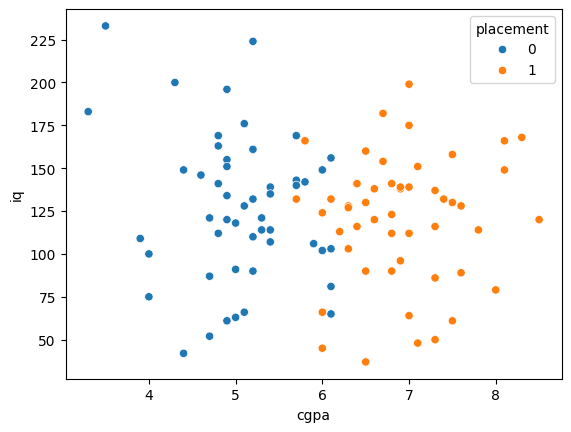

In [3]:
sns.scatterplot(x=df['cgpa'], y=df['iq'], data=df, hue=df['placement'])
plt.show()

In [4]:
x = df.iloc[:, :-1]
y = df['placement']

x.ndim, y.ndim

(2, 1)

In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=4)

In [6]:
svc = SVC(kernel="linear") # default kernel = rbf
svc.fit(x_train, y_train)

SVC(kernel='linear')

In [7]:
svc.score(x_test, y_test)

0.9

In [8]:
svc.score(x_train, y_train)

0.9125

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


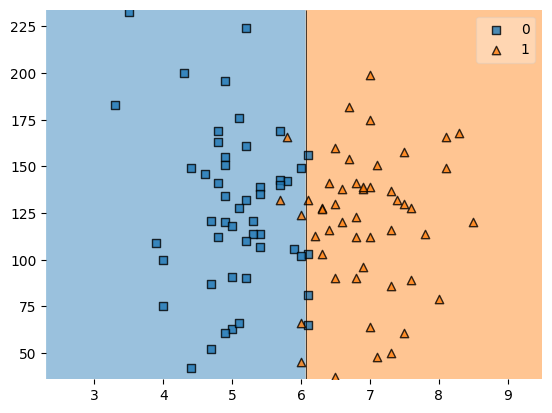

In [9]:
plot_decision_regions(x.to_numpy(), y.to_numpy(), clf=svc)
plt.show()

---

## Trying different kernels

In [10]:
svc1 = SVC(kernel="sigmoid") # 'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'
svc1.fit(x_train, y_train)

SVC(kernel='sigmoid')

In [11]:
svc1.score(x_test, y_test), svc1.score(x_train, y_train)

(0.4, 0.5)

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


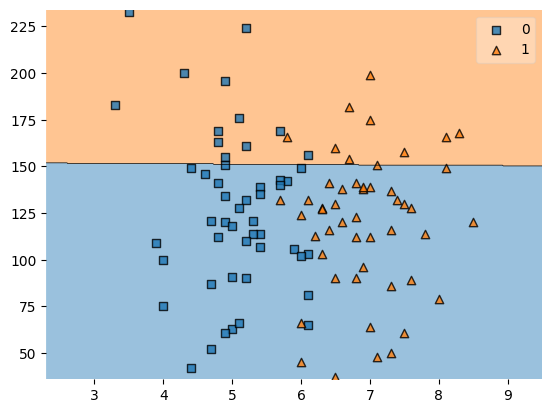

In [12]:
plot_decision_regions(x.to_numpy(), y.to_numpy(), clf=svc1)
plt.show()

---

## SVM Decision Boundary with Hyperplanes

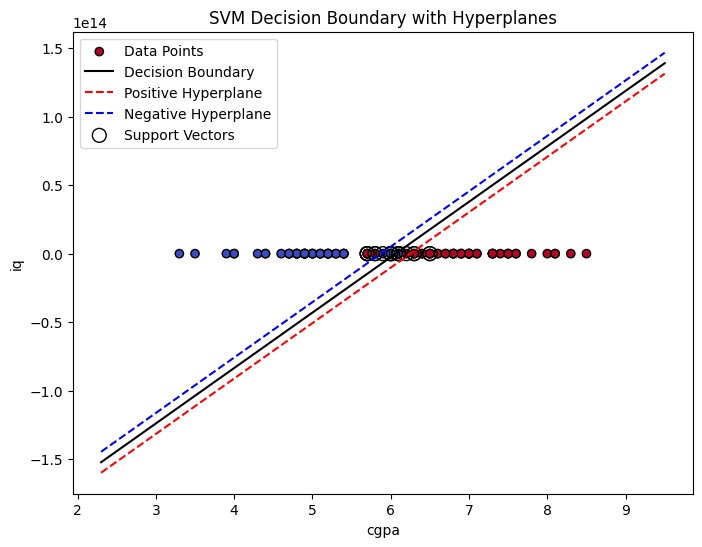

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

# Load dataset
df = pd.read_csv('../datasets/placement_classification.csv')

# Extract features and target
x = df.iloc[:, :-1].values  # Convert to NumPy array for visualization
y = df['placement'].values  

# Ensure only 2D features are used
if x.shape[1] != 2:
    raise ValueError("Hyperplane visualization works for 2D feature data. Select only 2 features.")

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=4)

# Train SVM model
svc2 = SVC(kernel="linear")
svc2.fit(x_train, y_train)

# Get the weight vector and bias term
w = svc2.coef_[0]  # Coefficients for the hyperplane
b = svc2.intercept_[0]  # Bias term

# Create a meshgrid for plotting decision boundary
x_min, x_max = x[:, 0].min() - 1, x[:, 0].max() + 1
y_min, y_max = x[:, 1].min() - 1, x[:, 1].max() + 1
xx = np.linspace(x_min, x_max, 100)

# Compute decision boundary: w1*x1 + w2*x2 + b = 0  ->  x2 = (-w1*x1 - b) / w2
decision_boundary = (-w[0] * xx - b) / w[1]

# Compute margin boundaries (parallel hyperplanes)
margin = 1 / np.linalg.norm(w)  # Distance from decision boundary
positive_hyperplane = (-w[0] * xx - b + margin) / w[1]
negative_hyperplane = (-w[0] * xx - b - margin) / w[1]

# Plot data points
plt.figure(figsize=(8, 6))
plt.scatter(x[:, 0], x[:, 1], c=y, cmap='coolwarm', edgecolors='k', label='Data Points')

# Plot decision boundary
plt.plot(xx, decision_boundary, 'k-', label='Decision Boundary')

# Plot margin hyperplanes
plt.plot(xx, positive_hyperplane, 'r--', label='Positive Hyperplane')
plt.plot(xx, negative_hyperplane, 'b--', label='Negative Hyperplane')

# Highlight support vectors
plt.scatter(svc2.support_vectors_[:, 0], svc2.support_vectors_[:, 1], s=100, facecolors='none', edgecolors='k', label='Support Vectors')

# Labels and legend
plt.xlabel('cgpa')
plt.ylabel('iq')
plt.title('SVM Decision Boundary with Hyperplanes')
plt.legend()
plt.show()


---